# Improve the bridge model on the data already on Hugging Face

Uses the chips already built in `AyaHassan/fair-bridges-chips`. **Nothing is rebuilt and OSM, OAM and IGN are not called.**
Images are taken first from an earlier YOLO export in this session (`/kaggle/working/yolo_bridges`), then from the HF cache, and only then from the Hub.

What this notebook changes compared with the first run (validation mAP50 0.44, OAM test mAP50 0.11):

| # | Change | Why |
|---|---|---|
| 1 | **New spatial split:** whole OAM *cities* from different countries as test; z14 blocks for validation (30 % of OAM blocks); bridges kept together; 1-chip buffer; pHash; 5 leakage tests | One test city (110 chips) was too noisy, and validation was 80 % France |
| 2 | **Label clean-up:** chips with culverts (< 12 m), tiny boxes, footbridges or edge slivers are left out of training and of the clean test set | The model can't see these, so they only add noise and cap recall |
| 3 | **Training:** `imgsz=512`, OAM chips repeated 3×, OAM-only validation, longer schedule, mosaic off for the last 30 epochs | Small bridges are easier to learn at a larger input size; best epoch is picked for OAM |
| 4 | **Stage 2:** short fine-tune on OAM only, with a low learning rate | Adapts the model to drone/OAM imagery |
| 5 | **Honest evaluation:** rotated-box P/R/F1 at IoU 0.3 and 0.5, threshold chosen on validation, clean vs raw test, recall by label category and size | Shows how much of the error is the model and how much is the labels |

Needs: **GPU T4/P100**, Internet on, `HF_TOKEN` secret. Run time ≈ 3–4 h (or ≈ 30 min with `QUICK = True`).

## 0 · Settings

In [1]:
QUICK = False                 # True: few epochs, to check the notebook end to end first
RUN_BASELINE = True           # same settings as the first run (256 px, no clean-up) on the NEW split, for a fair comparison
EXP = "exp2_clean_512"        # name of this experiment (folders, HF uploads)

DATASET_REPO = None           # None -> "<your user>/fair-bridges-chips"
MODEL_REPO = None             # None -> "<your user>/fair-bridges-yolo"

TEST_CITIES = None            # None -> suggested automatically (whole cities, max one per country); or e.g. ["dar_es_salaam", "lima"]
TEST_SHARE = 0.25             # share of OAM bridge chips that the suggestion aims to hold out
VAL_FRACTION = {"oam_osm": 0.30, "default": 0.15}

IGNORE = dict(min_len_m=12, min_long_px=16, min_short_px=4, sliver_visible=0.25, sliver_px=48, drop_footbridges=True)
OAM_REPEAT = 3
IMGSZ = 512
EPOCHS_1, EPOCHS_2 = (5, 3) if QUICK else (200, 40)

## 1 · Setup

In [2]:
import os, sys, subprocess, glob
ON_KAGGLE = os.path.exists("/kaggle")
ON_COLAB = "google.colab" in sys.modules
BASE = "/kaggle/working" if ON_KAGGLE else ("/content" if ON_COLAB else os.getcwd())

REPO_URL = "https://github.com/AYA0HASSAN/omdena-bridges-hf-builder.git"
REPO_DIR = f"{BASE}/HOTOSM-fAIr-Bridges"
CODE = f"{REPO_DIR}/experiments/bridges-hf-builder"
if os.path.exists(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=False)
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
os.chdir(CODE); sys.path.insert(0, CODE)
assert os.path.exists("bridgebuild/experiment.py"), "commit bridgebuild/experiment.py (and the updated finalize.py) to the repo first"
print("code:", os.getcwd())

Cloning into '/kaggle/working/HOTOSM-fAIr-Bridges'...


code: /kaggle/working/HOTOSM-fAIr-Bridges/experiments/bridges-hf-builder


In [3]:
!pip install -q -r requirements.txt ultralytics

In [4]:
if ON_KAGGLE:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
elif ON_COLAB:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
from huggingface_hub import whoami
me = whoami()["name"]
DATASET_REPO = DATASET_REPO or f"{me}/fair-bridges-chips"
MODEL_REPO = MODEL_REPO or f"{me}/fair-bridges-yolo"
print("dataset:", DATASET_REPO, "| models:", MODEL_REPO)

import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from bridgebuild.hub import HFHub
from bridgebuild import experiment as E
hub = HFHub(DATASET_REPO, private=True)
WORK = Path(BASE) / "bb_exp"; WORK.mkdir(exist_ok=True)
POOL = Path(BASE) / "bridges_pool"                     # every chip once; kept between experiments
REUSE = [f"{BASE}/yolo_bridges"] + glob.glob("/kaggle/input/*/yolo_bridges")   # earlier exports, if any

dataset: AyaHassan/fair-bridges-chips | models: AyaHassan/fair-bridges-yolo


## 2 · Load the index tables (a few MB, no images)

In [5]:
ch, br = E.load_tables(hub, WORK)
print(f"{len(ch)} chips, {int((ch.n_boxes > 0).sum())} with bridges, {len(br)} bridges")
display(ch.groupby(["source", "kind"]).size().unstack(fill_value=0))
print("OAM cities:")
display(E.city_table(ch))

index/bridges-00000.parquet: reconstructing file:   0%|          |  0.00B /  122kB            

index/bridges-00000.parquet: downloading bytes:           |  0.00B            

index/bridges-00001.parquet: reconstructing file:   0%|          |  0.00B /  154kB            

index/bridges-00001.parquet: downloading bytes:           |  0.00B            

index/bridges-00002.parquet: reconstructing file:   0%|          |  0.00B /  151kB            

index/bridges-00002.parquet: downloading bytes:           |  0.00B            

... (22 outputs left out)

2741 chips, 1436 with bridges, 2252 bridges


kind,hard_negative,positive,random_negative
source,,,
france,469,938,469
oam_osm,188,498,179


OAM cities:


,city,country,chips,positive,boxes,images,regions
0,port_au_prince,HT,537,276,336,3,1
1,dar_es_salaam,TZ,110,80,105,2,1
2,freetown,SL,97,58,70,3,1
3,monrovia,LR,72,48,185,4,1
4,manila,PH,22,16,24,1,1
5,beira,MZ,11,11,16,1,2
6,blantyre,MW,14,9,9,1,1


## 3 · Label clean-up rules
Each box gets a reason if the model can't be expected to see it. A chip with any such box is **left out** of training and of the clean test set. It is not used as a negative, because the bridge is still in the picture.

In [6]:
boxes = E.ignore_rules(E.box_table(ch, br), **IGNORE)
ignored = E.chip_ignore(boxes)
t = boxes.assign(reason=boxes["ignore"].replace("", "kept")).groupby(["source", "reason"]).size().unstack(0, fill_value=0)
display(t)
pos = ch[ch.n_boxes > 0]
print(f"chips left out: {len(ignored)} of {len(pos)} bridge chips "
      f"(OAM {sum(c.startswith('oam_osm') for c in ignored)}, France {sum(c.startswith('france') for c in ignored)})")

source,france,oam_osm
reason,,
edge sliver,131,26
footbridge,0,179
kept,943,332
short bridge <12 m (culvert?),74,185
tiny box <16x4 px,39,23


chips left out: 490 of 1436 bridge chips (OAM 265, France 225)


## 4 · Spatial split
Test = whole OAM cities, at most one per country, so the test measures a **new place**, not a neighbouring street. Validation = ~2.4 km blocks. A bridge never crosses splits, there's a 1-chip buffer between splits, and near-duplicate images are removed. The 5 leakage tests must all pass.

In [7]:
if TEST_CITIES is None:
    TEST_CITIES = E.suggest_test_cities(ch, share=TEST_SHARE)
print("test cities:", TEST_CITIES)
s, leak, split_cfg = E.spatial_split(ch, br, TEST_CITIES, val_fraction=VAL_FRACTION)
display(leak)
n_dup = int(ch.duplicated(["chip_id", "image_id"]).sum())
print(f"{n_dup} chips were cut twice from the same image (overlapping regions); the split keeps one copy")
assert leak["passed"].all(), "leakage test failed - change TEST_CITIES"
display(s.pivot_table(index=["source", "city"], columns="split", values="chip_id", aggfunc="count", fill_value=0))

test cities: ['dar_es_salaam', 'freetown']


,test,passed,violations,example
0,every chip in one split,True,0,[]
1,every bridge in one split,True,0,[]
2,no chips of different splits within 1 chip(s),True,0,[]
3,test holds only the test regions,True,0,[]
4,test images not used in train/val,True,0,[]


2 chips were cut twice from the same image (overlapping regions); the split keeps one copy


split                   buffer  drop  test  train  val
source  city                                          
france  lyon                22     0     0    678  218
        strasbourg           2     0     0    843  113
oam_osm beira                0     2     0     11    0
        blantyre             0     0     0      0   14
        dar_es_salaam        0     0   110      0    0
        freetown             0     0    97      0    0
        manila               0     0     0     22    0
        monrovia             0     0     0     17   55
        port_au_prince      10     0     0    343  184

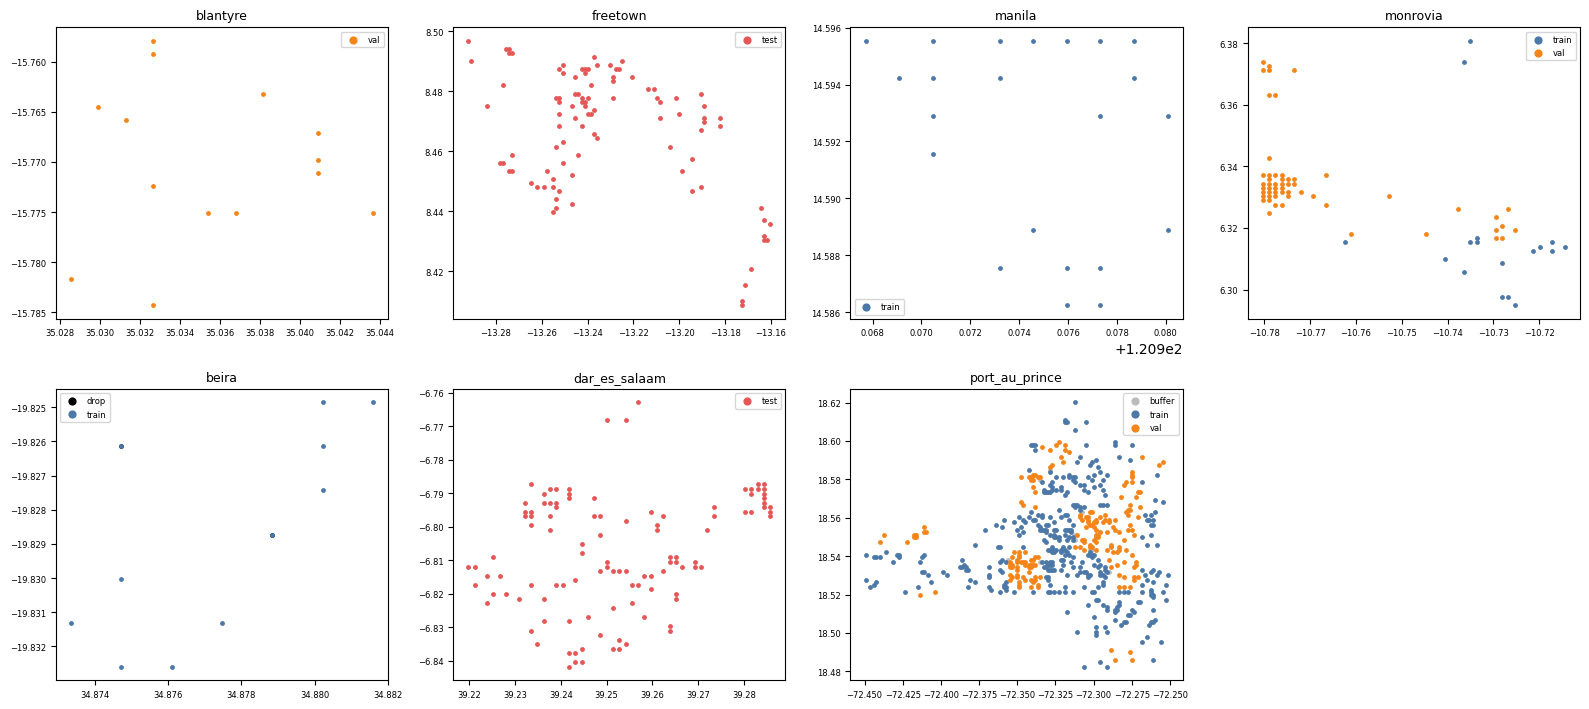

In [8]:
# Map of the split: each city should be all test, or train/val in blocks, with a gap between colours
col = {"train": "#4c78a8", "val": "#f58518", "test": "#e45756", "buffer": "#bbbbbb", "drop": "#000000"}
m = s.join(ch[["lon", "lat"]])
cities = [c for c in m[m.source == "oam_osm"].city.unique()]
n = len(cities); cols = min(4, n); rows = -(-n // cols)
fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows), squeeze=False)
for ax in axs.flat: ax.axis("off")
for ax, c in zip(axs.flat, cities):
    d = m[m.city == c]; ax.axis("on")
    for k, g in d.groupby("split"):
        ax.scatter(g.lon, g.lat, s=6, c=col.get(k, "k"), label=k)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=6); ax.legend(fontsize=6, markerscale=2)
plt.tight_layout(); plt.show()

## 5 · Image pool (each chip once on disk; downloads only what is missing)

In [9]:
E.build_pool(hub, s, POOL, reuse_dirs=REUSE)
print(len(list((POOL / "images").glob("*.png"))), "images in pool")

[pool] 2705 chips: 0 already in pool, 0 reused from earlier export, 2705 to read from 7 shard(s)


data/shard-00000.parquet: reconstructing file:   0%|          |  0.00B / 56.4MB            

data/shard-00000.parquet: downloading bytes:           |  0.00B            

[pool] shard 1/7 data/shard-00000.parquet


data/shard-00001.parquet: reconstructing file:   0%|          |  0.00B / 52.1MB            

data/shard-00001.parquet: downloading bytes:           |  0.00B            

... (12 outputs left out)

[pool] shard 6/7 data/shard-00005.parquet


data/shard-00006.parquet: reconstructing file:   0%|          |  0.00B / 29.9MB            

data/shard-00006.parquet: downloading bytes:           |  0.00B            

[pool] shard 7/7 data/shard-00006.parquet
2705 images in pool


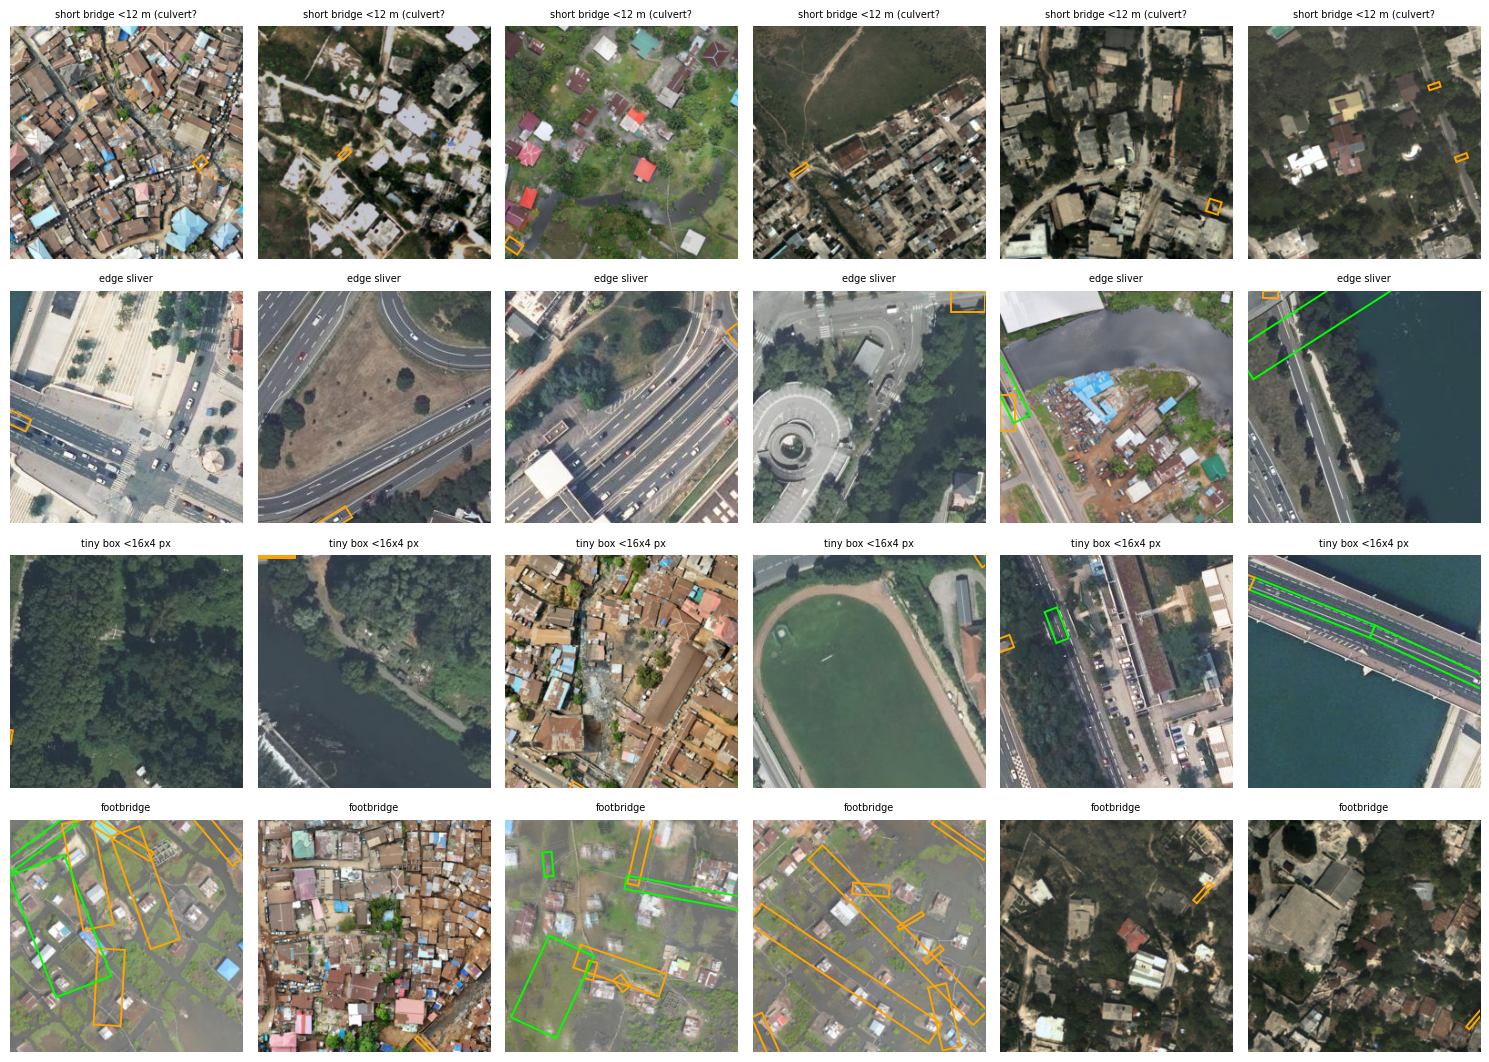

In [10]:
# Check the rules by eye: left-out boxes (orange) per reason
from PIL import Image
from matplotlib.patches import Polygon as P
reasons = [r for r in boxes["ignore"].unique() if r]
fig, axs = plt.subplots(len(reasons) or 1, 6, figsize=(15, 2.7 * max(1, len(reasons))), squeeze=False)
for ax in axs.flat: ax.axis("off")
for i, rsn in enumerate(reasons):
    smp = boxes[boxes.ignore == rsn].drop_duplicates("stem").sample(min(6, (boxes.ignore == rsn).sum()), random_state=0)
    for ax, r in zip(axs[i], smp.itertuples()):
        f = POOL / "images" / f"{r.stem}.png"
        if not f.exists(): continue
        ax.imshow(Image.open(f))
        for b in boxes[boxes.stem == r.stem].itertuples():
            c = np.array(json.loads(ch.loc[ch.stem == r.stem, "boxes_px"].iloc[0])[b.box]).reshape(4, 2)
            ax.add_patch(P(c, fill=False, ec="orange" if b.ignore else "lime", lw=1.4))
        ax.set_title(rsn[:28], fontsize=7)
plt.tight_layout(); plt.show()

## 6 · Experiment folders (symlinks into the pool, no copies)

In [11]:
EXP_DIR = WORK / EXP
counts = E.make_experiment(POOL, s, ignored, EXP_DIR, oam_repeat=OAM_REPEAT, val_sources=("oam_osm",))
display(counts)
if RUN_BASELINE:     # first-run settings on the new split: no clean-up, no repeat, val = all sources
    BASE_DIR = WORK / "exp_baseline_256"
    display(E.make_experiment(POOL, s, {}, BASE_DIR, oam_repeat=1, val_sources=("oam_osm", "france")))

,set,chips,positive,negative,boxes,oam_chips,files
0,train,1630,651,979,771,287,2204
1,train_oam,287,98,189,113,287,287
2,val,156,52,104,59,156,156
3,val_france,288,148,140,175,0,288
4,val_all,444,200,244,234,156,444
5,test,148,79,69,99,148,148
6,test_raw,207,138,69,175,207,207


,set,chips,positive,negative,boxes,oam_chips,files
0,train,1914,935,979,1184,393,1914
1,train_oam,393,204,189,260,393,393
2,val,584,340,244,542,253,584
3,val_france,331,191,140,241,0,331
4,val_all,584,340,244,542,253,584
5,test,207,138,69,175,207,207
6,test_raw,207,138,69,175,207,207


## 7 · Training

In [12]:
from ultralytics import YOLO
RUNS = Path(BASE) / "runs"
common = dict(degrees=180, flipud=0.5, fliplr=0.5, scale=0.3, hsv_h=0.02, hsv_v=0.3, workers=2, project=str(RUNS), exist_ok=True)

if RUN_BASELINE:
    YOLO("yolo26s-obb.pt").train(data=str(BASE_DIR / "data_stage1.yaml"), imgsz=256, epochs=min(100, EPOCHS_1), batch=64,
                                 patience=20, close_mosaic=10, name=f"{EXP}_baseline", **common)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bb_exp/exp_baseline_256/data_stage1.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=t

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      3.05G      2.487      3.303    0.06944     0.1837         47        256: 100% ━━━━━━━━━━━━ 30/30 5.2it/s 5.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.3it/s 3.1s.3ss
                   all        584        542    0.00626     0.0406   0.000998    0.00025

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss angle_loss  Instances       Size
      3/100      3.05G      2.533      3.325     0.0751     0.1823         48        256: 100% ━━━━━━━━━━━━ 30/30 5.3it/s 5.7s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.4it/s 2.9s.3ss
                   all        584        542    0.00458     0.0129   0.000379   7.76e-05

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss angle_loss  Instances       Size
      4/100      3.05G      2.604      3.435     0.0685      0.193         56        256: 100% ━━━━━━━━━━━━ 30/30 5.3i

In [13]:
# Stage 1: all clean data, OAM x3, OAM-only validation, 512 px
YOLO("yolo26s-obb.pt").train(data=str(EXP_DIR / "data_stage1.yaml"), imgsz=IMGSZ, epochs=EPOCHS_1, batch=32,
                             patience=50, close_mosaic=30, cos_lr=True, name=f"{EXP}_stage1", **common)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=30, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/bb_exp/exp2_clean_512/data_stage1.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.3, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp2_clean_512_stage1, nbs=64, nm

ultralytics.utils.metrics.OBBMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x784351736e40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [14]:
# Stage 2: fine-tune on OAM only, low learning rate (explicit optimizer, otherwise lr0 is ignored)
YOLO(str(RUNS / f"{EXP}_stage1" / "weights" / "best.pt")).train(
    data=str(EXP_DIR / "data_stage2.yaml"), imgsz=IMGSZ, epochs=EPOCHS_2, batch=32, patience=15, close_mosaic=10,
    optimizer="AdamW", lr0=2e-4, lrf=0.1, warmup_epochs=0, name=f"{EXP}_stage2", **common)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bb_exp/exp2_clean_512/data_stage2.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.3, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/exp2_clean_512_stage1/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scal

ultralytics.utils.metrics.OBBMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7843682b2d60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## 8 · Evaluation
The confidence threshold is chosen on **OAM validation** (best F1 at IoU 0.5) and then applied to test. The table reports:
- **test**: clean labels only. This is the honest number.
- **test_raw**: every label, comparable with the first run's 0.11.
- IoU 0.3 shows how much error comes from label offset, not detection.

In [15]:
MODELS = {"stage1": (RUNS / f"{EXP}_stage1/weights/best.pt", IMGSZ), "stage2": (RUNS / f"{EXP}_stage2/weights/best.pt", IMGSZ)}
if RUN_BASELINE:
    MODELS = {"baseline_256": (RUNS / f"{EXP}_baseline/weights/best.pt", 256), **MODELS}

rows, keep = [], {}
for name, (w, sz) in MODELS.items():
    if not Path(w).exists(): print("missing", w); continue
    model = YOLO(str(w))
    pv = E.predict_set(model, EXP_DIR / "images/val", imgsz=sz)
    dv, gv = E.match(pv, EXP_DIR / "labels/val"); swv = E.sweep(dv, gv)
    conf = E.best_conf(swv, 0.5)
    for split in ["val", "val_france", "test", "test_raw"]:
        if not any((EXP_DIR / "images" / split).iterdir()): continue
        p = pv if split == "val" else E.predict_set(model, EXP_DIR / "images" / split, imgsz=sz)
        d, g = E.match(p, EXP_DIR / "labels" / split); sw = E.sweep(d, g)
        mp = model.val(data=str(EXP_DIR / f"eval_{split}.yaml"), imgsz=sz, batch=32, verbose=False, plots=False)
        for r in E.at_conf(sw, conf).itertuples():
            rows.append({"model": name, "set": split, "conf": conf, "IoU": r.iou_thr, "precision": r.precision,
                         "recall": r.recall, "F1": r.f1, "mAP50": mp.results_dict["metrics/mAP50(B)"], "boxes": r.gt})
        keep[(name, split)] = (d, g, p, conf)
res = pd.DataFrame(rows)
display(res.pivot_table(index=["set", "model"], columns="IoU", values=["precision", "recall", "F1"]).round(3))
display(res.drop_duplicates(["model", "set"])[["model", "set", "conf", "mAP50", "boxes"]].round(3))
res.to_csv(WORK / f"{EXP}_metrics.csv", index=False)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s-obb summary (fused): 129 layers, 9,751,554 parameters, 0 gradients, 21.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2129.3±385.3 MB/s, size: 114.4 KB)
val: Scanning /kaggle/working/bb_exp/exp2_clean_512/labels/val.cache... 156 images, 104 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 156/156 59.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.4it/s 1.1s0.2s
                   all        156         59      0.422      0.186      0.194     0.0642
Speed: 0.2ms preprocess, 2.9ms inference, 0.0ms loss, 1.5ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s-obb summary (fused): 129 layers, 9,751,554 parameters, 0 gradients, 21.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2507.7±671.8 MB/s, size: 103.7 KB)
val: Scanning /kaggle/working/bb_

F1        precision        recall       
IoU                        0.3    0.5       0.3    0.5    0.3    0.5
set        model                                                    
test       baseline_256  0.341  0.109     0.733  0.233  0.222  0.071
           stage1        0.370  0.148     0.694  0.278  0.253  0.101
           stage2        0.411  0.217     0.474  0.250  0.364  0.192
test_raw   baseline_256  0.225  0.075     0.632  0.211  0.137  0.046
           stage1        0.270  0.099     0.638  0.234  0.171  0.063
           stage2        0.297  0.155     0.389  0.204  0.240  0.126
val        baseline_256  0.254  0.169     0.750  0.500  0.153  0.102
           stage1        0.270  0.162     0.667  0.400  0.169  0.102
           stage2        0.330  0.191     0.339  0.196  0.322  0.186
val_france baseline_256  0.690  0.460     0.783  0.522  0.617  0.411
           stage1        0.631  0.423     0.764  0.512  0.537  0.360
           stage2        0.592  0.345     0.568  0.332  0.617  0.360

,model,set,conf,mAP50,boxes
0,baseline_256,val,0.25,0.194,59
2,baseline_256,val_france,0.25,0.626,175
4,baseline_256,test,0.25,0.247,99
6,baseline_256,test_raw,0.25,0.153,175
8,stage1,val,0.25,0.218,59
10,stage1,val_france,0.25,0.577,175
12,stage1,test,0.25,0.242,99
14,stage1,test_raw,0.25,0.149,175
16,stage2,val,0.10,0.206,59
18,stage2,val_france,0.10,0.565,175


In [16]:
# Why bridges are missed (test_raw, best model at its validation threshold, IoU 0.3)
BEST = "stage2" if ("stage2", "test_raw") in keep else "stage1"
d, g, p, conf = keep[(BEST, "test_raw")]
cat, size = E.recall_by_category(g, boxes, conf, iou_thr=0.3)
print("model:", BEST, "| conf:", conf); display(cat.round(3)); display(size.round(3))

model: stage2 | conf: 0.1


,category,boxes,recall
0,clean label,114,0.333
1,edge sliver,9,0.000
2,footbridge,11,0.000
3,short bridge <12 m (culvert?),35,0.114
4,tiny box <16x4 px,6,0.000


,size,boxes,recall
0,<16,20,0.050
1,16-32,63,0.159
2,32-64,49,0.408
3,64-128,27,0.259
4,>128,16,0.250


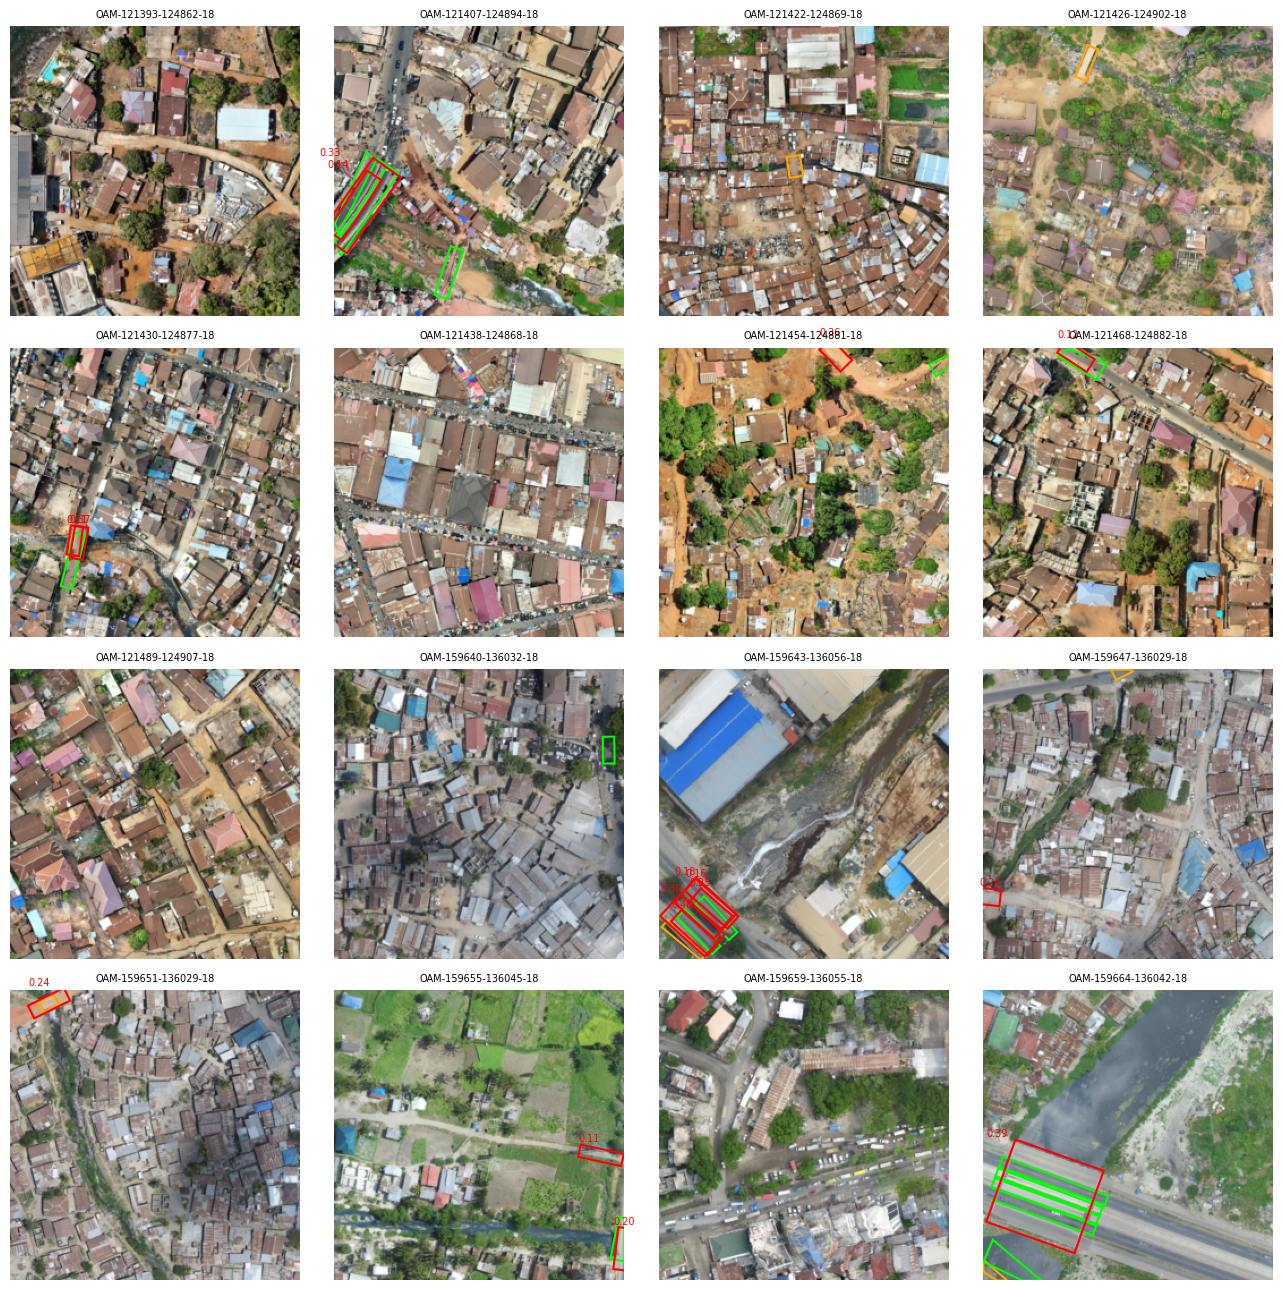

In [17]:
# Test predictions (red) vs labels (green = clean, orange = left-out category)
d, g, p, conf = keep[(BEST, "test_raw")]
stems = sorted(p)[:: max(1, len(p) // 16)][:16]
fig, axs = plt.subplots(4, 4, figsize=(13, 13))
for ax, st in zip(axs.flat, stems):
    ax.axis("off"); ax.imshow(Image.open(EXP_DIR / "images/test_raw" / f"{st}.png"))
    gt = E.read_gt(EXP_DIR / "labels/test_raw" / f"{st}.txt")
    bx = boxes[boxes.stem == st].set_index("box")["ignore"].to_dict()
    for j, c in enumerate(gt):
        ax.add_patch(P(c, fill=False, ec="orange" if bx.get(j) else "lime", lw=1.5))
    pp, cc = p[st]
    for c, cf in zip(pp, cc):
        if cf >= conf:
            ax.add_patch(P(c, fill=False, ec="red", lw=1.5)); ax.text(c[:, 0].min(), c[:, 1].min() - 2, f"{cf:.2f}", color="red", fontsize=7)
    ax.set_title(st, fontsize=7)
plt.tight_layout(); plt.savefig(WORK / f"{EXP}_test_predictions.png", dpi=110); plt.show()

## 9 · Save to Hugging Face
Weights, metrics and the split go to the model repo. The split is also saved in the dataset repo under `splits/`, so the experiment can be repeated exactly.

In [18]:
from huggingface_hub import HfApi
api = HfApi()
api.create_repo(MODEL_REPO, repo_type="model", private=True, exist_ok=True)
sp = WORK / f"{EXP}_split.parquet"
s.assign(ignored=s.chip_id.map(lambda c: ignored.get(c, "")))[["chip_id", "image_id", "source", "city", "split", "reason", "ignored"]].to_parquet(sp, index=False)
(WORK / f"{EXP}_settings.json").write_text(json.dumps({"test_cities": TEST_CITIES, "val_fraction": VAL_FRACTION, "ignore": IGNORE,
    "oam_repeat": OAM_REPEAT, "imgsz": IMGSZ, "epochs": [EPOCHS_1, EPOCHS_2], "leakage_passed": bool(leak.passed.all())}, indent=1))
for name in ["stage1", "stage2", "baseline"]:
    wd = RUNS / f"{EXP}_{name}"
    if (wd / "weights/best.pt").exists():
        api.upload_file(path_or_fileobj=str(wd / "weights/best.pt"), path_in_repo=f"{EXP}/{name}/best.pt", repo_id=MODEL_REPO, repo_type="model")
        if (wd / "results.csv").exists():
            api.upload_file(path_or_fileobj=str(wd / "results.csv"), path_in_repo=f"{EXP}/{name}/results.csv", repo_id=MODEL_REPO, repo_type="model")
for f in [sp, WORK / f"{EXP}_settings.json", WORK / f"{EXP}_metrics.csv", WORK / f"{EXP}_test_predictions.png"]:
    if f.exists():
        api.upload_file(path_or_fileobj=str(f), path_in_repo=f"{EXP}/{f.name}", repo_id=MODEL_REPO, repo_type="model")
hub.commit({f"splits/{EXP}.parquet": sp}, f"split for {EXP} (test cities: {', '.join(TEST_CITIES)})")
print("saved to", f"https://huggingface.co/{MODEL_REPO}/tree/main/{EXP}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (4 outputs left out)

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

saved to https://huggingface.co/AyaHassan/fair-bridges-yolo/tree/main/exp2_clean_512


## 10 · Reading the results

1. **Stage 2 is the best model to ship as the baseline.** It has the best OAM F1 at both IoU levels.
2. **Most of that gain comes from the threshold, not a better model.** mAP50, which doesn't depend on the threshold, is flat at 0.23–0.25 for all three models. Stage 2 mostly gains recall, from 0.07 to 0.19, at a lower threshold. With 59 validation and 99 test bridges, differences under about ±0.03 are noise.
3. **Location is a big part of the error.** F1 roughly doubles from IoU 0.5 to IoU 0.3 (0.22 → 0.41). The model finds bridges but its boxes are shifted or the wrong shape against OSM. That fits the OSM offset we measured earlier.
4. **The clean-up was justified.** At IoU 0.3, recall is 0.33 on clean labels, 0.11 on culverts, and 0 on slivers, tiny boxes and footbridges. In the rule-check picture, the "footbridges" in Monrovia are long boxes over flooded houses, which are bad OSM data.
5. **Small bridges are the weak spot.** Recall is 0.05 for boxes under 16 px and 0.16 for 16–32 px, against 0.41 for 32–64 px.
6. **The real bottleneck is data.** The OAM-only training set has **98 clean bridge chips**. France performs well (mAP50 0.57–0.63) with about 550, more than five times as many. The OAM fine-tune costs some French accuracy (0.63 → 0.57), which is fine for a model aimed at OAM.